In [2]:

# ============================================================
# 1. ENVIRONMENT AND PROJECT CHECKS
# ============================================================

import sys
from pathlib import Path

import torch
import torchvision

# Set the project root directory
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "src").exists():
    PROJECT_DIR = PROJECT_DIR.parent

sys.path.insert(0, str(PROJECT_DIR))

from src.config import DATA_DIR, IMAGE_SIZE, BATCH_SIZE, DEVICE

# Check Python environment
print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

# Check GPU availability
print("\nDevice:", DEVICE)
print("CUDA available:", torch.cuda.is_available())
print("MPS available:", torch.backends.mps.is_available())

# Check project configuration
print("\nProject directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)


Python: 3.12.4
Interpreter: /Users/emanuelepasquini/.pyenv/versions/XAIvenv/bin/python
PyTorch: 2.14.1
Torchvision: 0.29.1

Device: mps
CUDA available: False
MPS available: True

Project directory: /Users/emanuelepasquini/Library/CloudStorage/GoogleDrive-emanuele.pasquini@edu.unifi.it/Il mio Drive/università/MAGISTRALE/pw explainable/xai-counterfactuals
Data directory: /Users/emanuelepasquini/Library/CloudStorage/GoogleDrive-emanuele.pasquini@edu.unifi.it/Il mio Drive/università/MAGISTRALE/pw explainable/xai-counterfactuals/data
Image size: 224
Batch size: 32


Number of real images: 5000
Image name: 00000.png
Image size: (1024, 1024)
Image mode: RGB


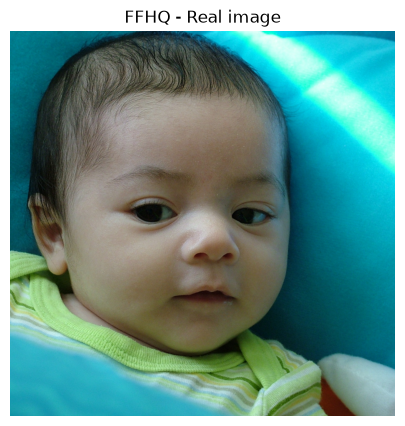

In [3]:

# ============================================================
# 2. FFHQ DATASET CHECK
# ============================================================

from PIL import Image
import matplotlib.pyplot as plt

# Directory containing the real images
real_dir = DATA_DIR / "real"

# List available images
image_files = sorted(real_dir.glob("*.png"))

print("Number of real images:", len(image_files))

if len(image_files) > 0:

    # Open the first image
    image = Image.open(image_files[0])

    print("Image name:", image_files[0].name)
    print("Image size:", image.size)
    print("Image mode:", image.mode)

    # Display the image
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title("FFHQ - Real image")
    plt.show()

else:
    print("No PNG images found in the directory.")


In [4]:

# ============================================================
# 2. DATASET LOADING TEST
# ============================================================

from src.dataset import get_dataloaders
from torchvision.datasets import ImageFolder

# Check the number of available images
real_dir = DATA_DIR / "real"
fake_dir = DATA_DIR / "fake"

extensions = {".jpg", ".jpeg", ".png", ".webp"}

n_real = sum(
    1 for file in real_dir.glob("*")
    if file.suffix.lower() in extensions
)

n_fake = sum(
    1 for file in fake_dir.glob("*")
    if file.suffix.lower() in extensions
)

print("Real images:", n_real)
print("Fake images:", n_fake)

if n_real == 0 or n_fake == 0:
    print("\nDataset not ready: real and fake images are required.")

else:
    # Check class encoding
    dataset = ImageFolder(root=DATA_DIR)
    print("\nClasses:", dataset.class_to_idx)

    # Load training, validation and test sets
    train_loader, val_loader, test_loader = get_dataloaders()

    print("\nTraining samples:", len(train_loader.dataset))
    print("Validation samples:", len(val_loader.dataset))
    print("Test samples:", len(test_loader.dataset))

    # Inspect the first batch
    images, labels = next(iter(train_loader))

    print("\nImages shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Labels:", labels.tolist())


Real images: 5000
Fake images: 5000

Classes: {'fake': 0, 'real': 1}

Training samples: 7000
Validation samples: 1500
Test samples: 1500

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Labels: [0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0]


In [5]:
# CONTROLLO STRATIFICAZIONE

# Check class distribution in each subset
for name, loader in [
    ("Train", train_loader),
    ("Validation", val_loader),
    ("Test", test_loader)
]:
    subset = loader.dataset
    labels = [subset.dataset.targets[i] for i in subset.indices]

    print(f"{name}: fake={labels.count(0)}, real={labels.count(1)}")


Train: fake=3500, real=3500
Validation: fake=750, real=750
Test: fake=750, real=750


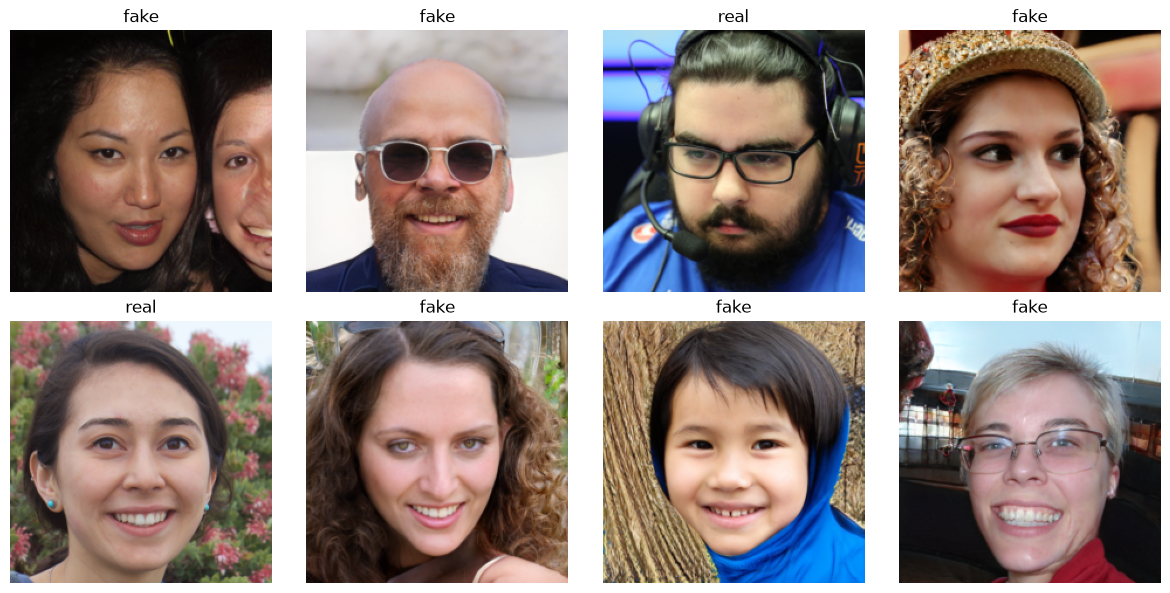

In [6]:

# ============================================================
# 4. VISUALIZE A MINI-BATCH
# ============================================================

import matplotlib.pyplot as plt

# Extract one batch
images, labels = next(iter(train_loader))

# ImageNet normalization parameters
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    # Undo normalization for visualization
    image = images[i] * std + mean

    # Convert from (C, H, W) to (H, W, C)
    image = image.permute(1, 2, 0).clamp(0, 1)      ### richiesto da matplotlib

    ax.imshow(image)
    ax.set_title(dataset.classes[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [6]:

# ============================================================
# 5. RESNET18 MODEL CHECK
# verificare soltanto che ResNet18 funziona
# ============================================================

from src.models import ResNet18Classifier

# Load the pretrained model
model = ResNet18Classifier()
model = model.to(DEVICE)
model.eval()

# Take 4 images from the training DataLoader
images, labels = next(iter(train_loader))
images = images[:4].to(DEVICE)

# Forward pass without gradient computation
with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("\nModel logits:")
print(outputs)

probabilities = torch.softmax(outputs, dim=1)
print("Class probabilities:")
print(probabilities)


Input shape: torch.Size([4, 3, 224, 224])
Output shape: torch.Size([4, 2])

Model logits:
tensor([[-0.2035,  0.3104],
        [-0.4655,  0.0167],
        [ 0.0181,  0.1091],
        [-0.5061,  0.5754]], device='mps:0')
Class probabilities:
tensor([[0.3743, 0.6257],
        [0.3817, 0.6183],
        [0.4772, 0.5228],
        [0.2532, 0.7468]], device='mps:0')


In [7]:

# ============================================================
# 6. FREEZE PRETRAINED LAYERS: FEATURE EXTRACTION
# ============================================================

# Freeze all pretrained parameters
for parameter in model.parameters():
    parameter.requires_grad = False

# Keep the final classification layer trainable
for parameter in model.model.fc.parameters():
    parameter.requires_grad = True

# Count trainable parameters
total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)


Total parameters: 11177538
Trainable parameters: 1026


In [7]:

# ============================================================
# 7. VALIDATION CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix
from src.config import CHECKPOINT_DIR
from src.models import ResNet18Classifier

# Load the best trained checkpoint
model = ResNet18Classifier().to(DEVICE)

model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "resnet18_10k_lr1e-3.pth",
        map_location=DEVICE,
        weights_only=True
    )
)

model.eval()

true_labels = []
predicted_labels = []

with torch.no_grad():
    for images, labels in val_loader:

        outputs = model(images.to(DEVICE))
        predictions = outputs.argmax(dim=1)

        true_labels.extend(labels.tolist())
        predicted_labels.extend(predictions.cpu().tolist())

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=[0, 1]
)

print("Classes: 0 = fake, 1 = real")
print("\nConfusion matrix:")
print(cm)


RuntimeError: Error(s) in loading state_dict for ResNet18Classifier:
	Missing key(s) in state_dict: "model.fc.1.weight", "model.fc.1.bias". 
	Unexpected key(s) in state_dict: "model.fc.weight", "model.fc.bias". 

In [9]:
print("Validation accuracy from confusion matrix:")
print((cm[0, 0] + cm[1, 1]) / cm.sum())

print("Validation samples:", len(val_loader.dataset))

Validation accuracy from confusion matrix:


NameError: name 'cm' is not defined

In [10]:

# ============================================================
# 9. DATA AUGMENTATION VERIFICATION
# ============================================================

from src.dataset import get_dataloaders

train_loader, val_loader, test_loader = get_dataloaders()

# Check dataset sizes and class distributions
for name, loader in [
    ("Train", train_loader),
    ("Validation", val_loader),
    ("Test", test_loader)
]:
    subset = loader.dataset
    labels = [subset.dataset.targets[i] for i in subset.indices]

    print(f"{name}: {len(subset)} images")
    print(f"  Fake: {labels.count(0)}, Real: {labels.count(1)}")

# Check preprocessing pipelines
print("\nTraining transforms:")
print(train_loader.dataset.dataset.transform)

print("\nValidation transforms:")
print(val_loader.dataset.dataset.transform)


Train: 7000 images
  Fake: 3500, Real: 3500
Validation: 1500 images
  Fake: 750, Real: 750
Test: 1500 images
  Fake: 750, Real: 750

Training transforms:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation transforms:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


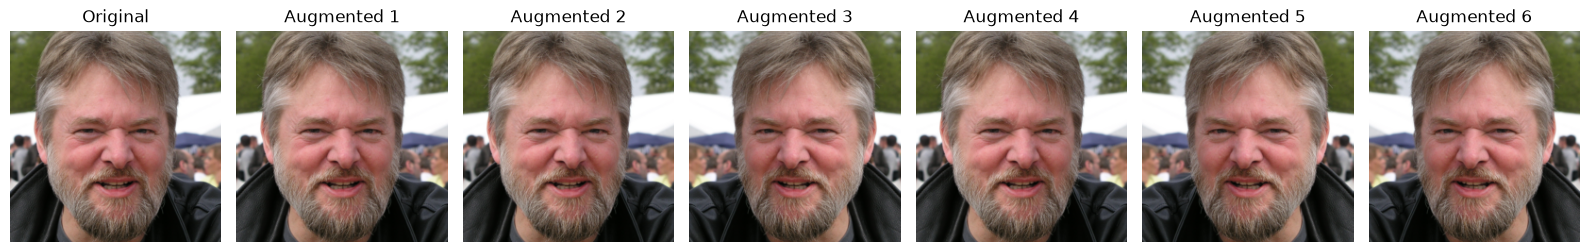

In [11]:

# ============================================================
# 10. VISUALIZE DATA AUGMENTATION
# ============================================================

import torch
import matplotlib.pyplot as plt

# Same image, with and without augmentation
dataset_train = train_loader.dataset.dataset
dataset_eval = val_loader.dataset.dataset

idx = train_loader.dataset.indices[0]

# ImageNet normalization parameters
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(1, 7, figsize=(16, 3))

for i, ax in enumerate(axes):

    if i == 0:
        image, label = dataset_eval[idx]
        title = "Original"
    else:
        image, label = dataset_train[idx]
        title = f"Augmented {i}"

    # Undo normalization
    image = image * std + mean
    image = image.permute(1, 2, 0).clamp(0, 1)

    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


Checkpoint: resnet50_exp10_scheduler_earlystop.pth

Confusion Matrix:
[[705  45]
 [ 77 673]]

Classification Report:
              precision    recall  f1-score   support

        Fake      0.902     0.940     0.920       750
        Real      0.937     0.897     0.917       750

    accuracy                          0.919      1500
   macro avg      0.919     0.919     0.919      1500
weighted avg      0.919     0.919     0.919      1500



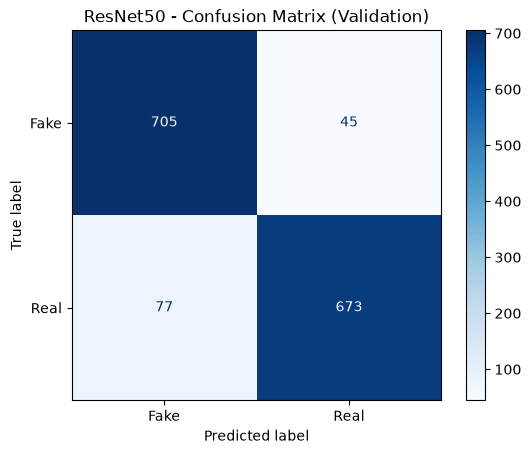

In [8]:

# ============================================================
# CONFUSION MATRIX - RESNET50 - VALIDATION SET
# ============================================================

import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from src.dataset import *
from src.models import ResNet50Classifier
from src.config import DEVICE, CHECKPOINT_DIR

# Checkpoint EXP10
checkpoint_path = CHECKPOINT_DIR / "resnet50_exp10_scheduler_earlystop.pth"

# Load validation data
_, val_loader, _ = get_dataloaders()

# Load best ResNet50 checkpoint
model = ResNet50Classifier().to(DEVICE)

model.load_state_dict(
    torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
)
model.eval()

# Collect predictions
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(DEVICE)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

print("Checkpoint:", checkpoint_path.name)
print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Fake", "Real"],
    digits=3
))

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake", "Real"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ResNet50 - Confusion Matrix (Validation)")
plt.show()


In [14]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from src.config import DATA_DIR, IMAGE_SIZE, BATCH_SIZE

# Validation dataset with Gaussian Blur
blur_dataset = datasets.ImageFolder(
    root=DATA_DIR,
    transform=transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.GaussianBlur(kernel_size=5, sigma=1.0),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])
)

# Use exactly the same validation indices
val_indices = val_loader.dataset.indices

val_blur_loader = DataLoader(
    Subset(blur_dataset, val_indices),
    batch_size=BATCH_SIZE,
    shuffle=False
)


In [ ]:

def evaluate_accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)                 # è stato caricato il modello ResNet18 con i pesi del checkpoint
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return correct / total


original_acc = evaluate_accuracy(model, val_loader)
blur_acc = evaluate_accuracy(model, val_blur_loader)

print(f"Original validation accuracy: {original_acc:.4f}")
print(f"Blurred validation accuracy:  {blur_acc:.4f}")


Original validation accuracy: 0.7833
Blurred validation accuracy:  0.7013
